In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path


In [7]:


FEAT = Path("../data/processed/features")
PROC = Path("../data/processed")
FIG  = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)

# ---- Brand palette (used consistently across all charts) ----
PALETTE = {
    "primary":    "#1f4e79",   # deep blue
    "accent":     "#f2a900",   # amber
    "renewable":  "#2ca02c",   # green
    "fossil":     "#d62728",   # red
    "neutral":    "#7f7f7f",   # grey
    "bg":         "#fbfbfb",
}
FUEL_COLORS = {
    "Electricity":                "#f2a900",
    "Natural gas":                "#3b6fb6",
    "Oil and petroleum products": "#8c564b",
    "Primary solid biofuels":     "#2ca02c",
    "Renewables and biofuels":    "#1b9e77",
    "Heat":                       "#d62728",
    "Solid fossil fuels, peat, peat products, oil shale and oil sands": "#4d4d4d",
}

plt.rcParams.update({
    "figure.facecolor": PALETTE["bg"],
    "axes.facecolor":   PALETTE["bg"],
    "axes.edgecolor":   "#333333",
    "axes.titleweight": "bold",
    "axes.titlesize":   14,
    "axes.labelsize":   11,
    "axes.grid":        True,
    "grid.alpha":       0.25,
    "grid.linestyle":   "--",
    "font.family":      "DejaVu Sans",
    "legend.frameon":   False,
})

def polish(ax, title, xlabel="", ylabel=""):
    ax.set_title(title, pad=12, loc="left")
    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    return ax

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())

master = pd.read_csv(FEAT / "features_country_year.csv")
fuel   = pd.read_csv(FEAT / "features_fuel_level.csv")
enduse = pd.read_csv(FEAT / "features_enduse_level.csv")

"Loaded ✅"

'Loaded ✅'

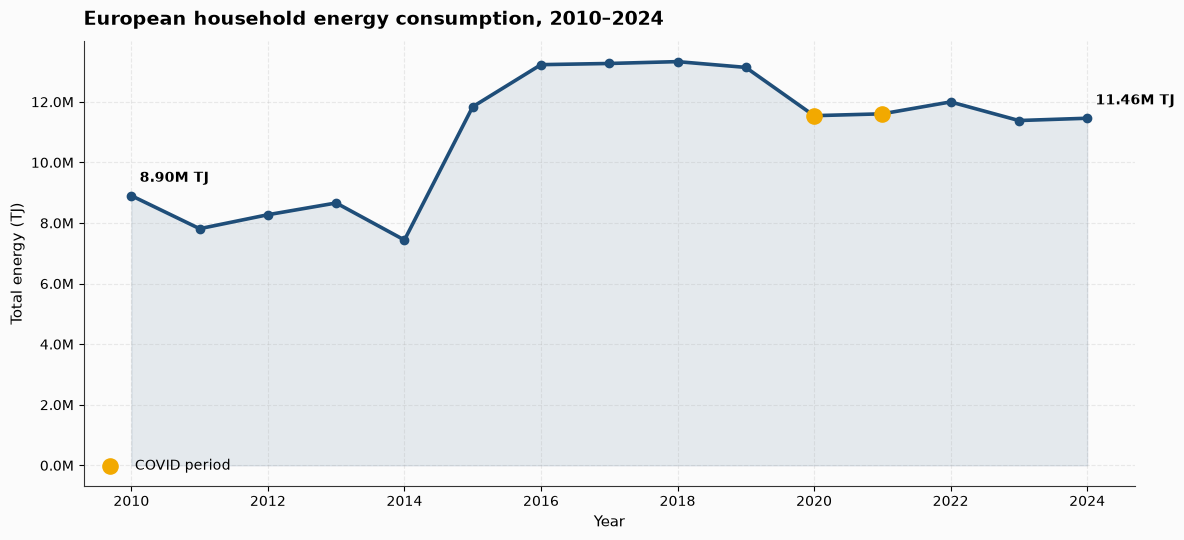

In [8]:
yearly = master.groupby("year").total_tj.sum().reset_index()

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(yearly.year, yearly.total_tj, color=PALETTE["primary"], linewidth=2.6, marker="o")
ax.fill_between(yearly.year, yearly.total_tj, color=PALETTE["primary"], alpha=0.10)
polish(ax, "European household energy consumption, 2010–2024", "Year", "Total energy (TJ)")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))

# Highlight COVID bump
covid = yearly[yearly.year.isin([2020, 2021])]
ax.scatter(covid.year, covid.total_tj, color=PALETTE["accent"], s=120, zorder=5, label="COVID period")
ax.legend(loc="lower left")

for y in [2010, 2024]:
    row = yearly[yearly.year == y].iloc[0]
    ax.annotate(f"{row.total_tj/1e6:.2f}M TJ",
                xy=(row.year, row.total_tj), xytext=(6, 10),
                textcoords="offset points", fontweight="bold")

plt.tight_layout(); save(fig, "fig01_total_trend"); plt.show()

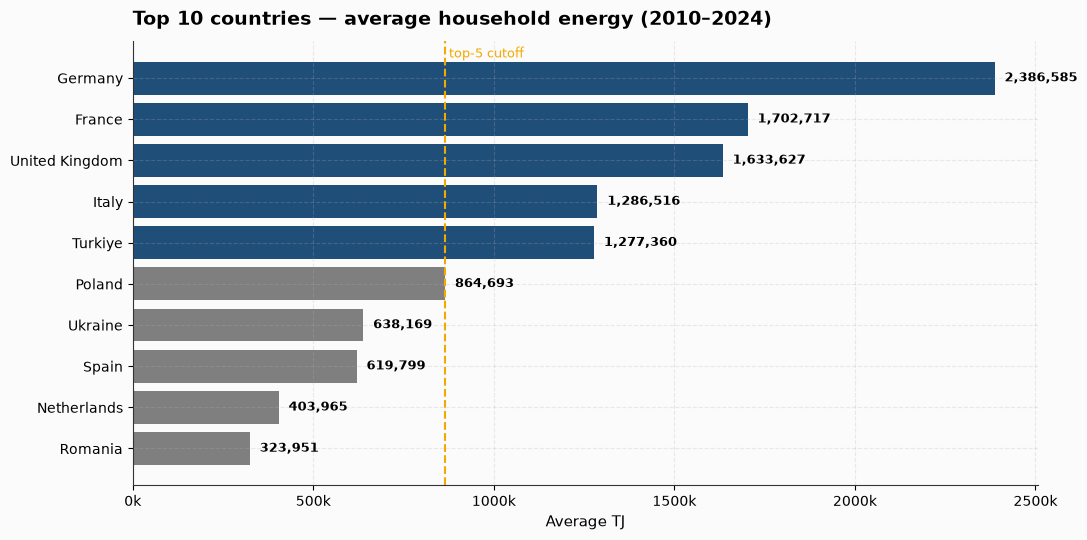

In [9]:
top10 = (master.groupby("country").total_tj.mean()
         .sort_values(ascending=False).head(10))

fig, ax = plt.subplots(figsize=(11, 5.5))
colors = [PALETTE["primary"]] * 5 + [PALETTE["neutral"]] * 5
ax.barh(top10.index[::-1], top10.values[::-1], color=colors[::-1])
polish(ax, "Top 10 countries — average household energy (2010–2024)", "Average TJ", "")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:.0f}k"))
for i, v in enumerate(top10.values[::-1]):
    ax.text(v, i, f"  {v:,.0f}", va="center", fontsize=9, fontweight="bold")

ax.axvline(top10.iloc[5], color=PALETTE["accent"], linestyle="--", linewidth=1.5)
ax.text(top10.iloc[5], 9.5, " top-5 cutoff", color=PALETTE["accent"], fontsize=9)

plt.tight_layout(); save(fig, "fig02_top10"); plt.show()

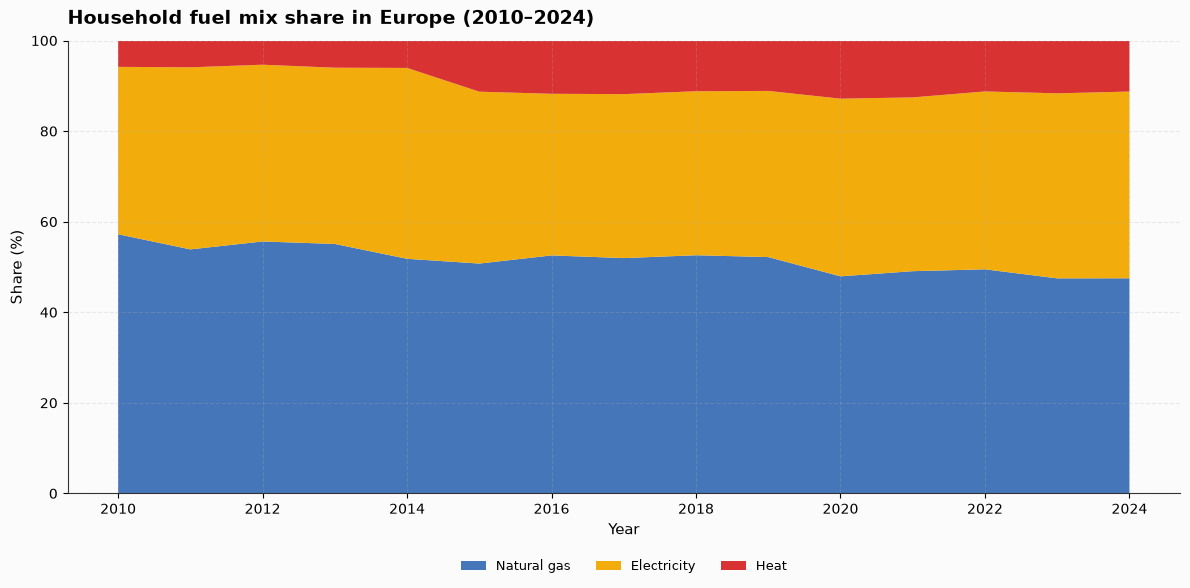

In [10]:
mix = (fuel[(fuel.level == "primary")]
       .pivot_table(index="year", columns="fuel", values="energy_tj", aggfunc="sum")
       .fillna(0))
mix_share = mix.div(mix.sum(axis=1), axis=0) * 100
order = mix_share.mean().sort_values(ascending=False).index.tolist()
mix_share = mix_share[order]

fig, ax = plt.subplots(figsize=(12, 6))
colors = [FUEL_COLORS.get(f, PALETTE["neutral"]) for f in order]
ax.stackplot(mix_share.index, [mix_share[f] for f in order],
             labels=order, colors=colors, alpha=0.95)
polish(ax, "Household fuel mix share in Europe (2010–2024)", "Year", "Share (%)")
ax.set_ylim(0, 100)
ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.12), fontsize=9)
plt.tight_layout(); save(fig, "fig03_fuel_mix"); plt.show()

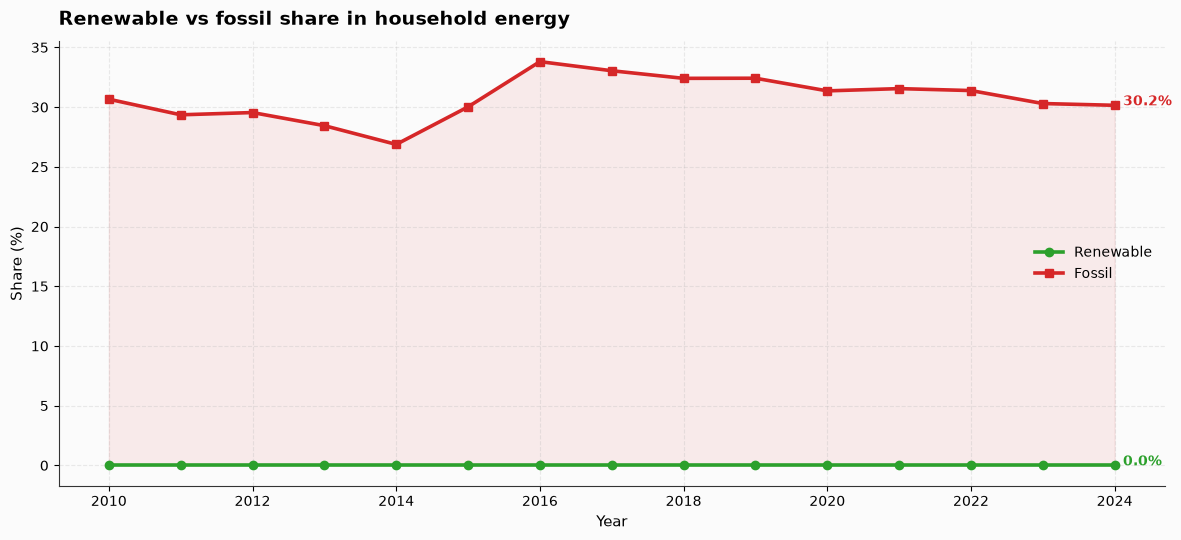

In [11]:
trend = master.groupby("year")[["renewable_share_pct", "fossil_share_pct"]].mean()

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(trend.index, trend.renewable_share_pct, marker="o", linewidth=2.6,
        color=PALETTE["renewable"], label="Renewable")
ax.plot(trend.index, trend.fossil_share_pct, marker="s", linewidth=2.6,
        color=PALETTE["fossil"], label="Fossil")
ax.fill_between(trend.index, trend.renewable_share_pct, color=PALETTE["renewable"], alpha=0.10)
ax.fill_between(trend.index, trend.fossil_share_pct, color=PALETTE["fossil"], alpha=0.08)
polish(ax, "Renewable vs fossil share in household energy", "Year", "Share (%)")
ax.legend(loc="center right")

for name, s in [("Renewable", trend.renewable_share_pct), ("Fossil", trend.fossil_share_pct)]:
    ax.annotate(f"{s.iloc[-1]:.1f}%", xy=(s.index[-1], s.iloc[-1]), xytext=(6, 0),
                textcoords="offset points", fontweight="bold", color=PALETTE[name.lower()])

plt.tight_layout(); save(fig, "fig04_renew_fossil"); plt.show()

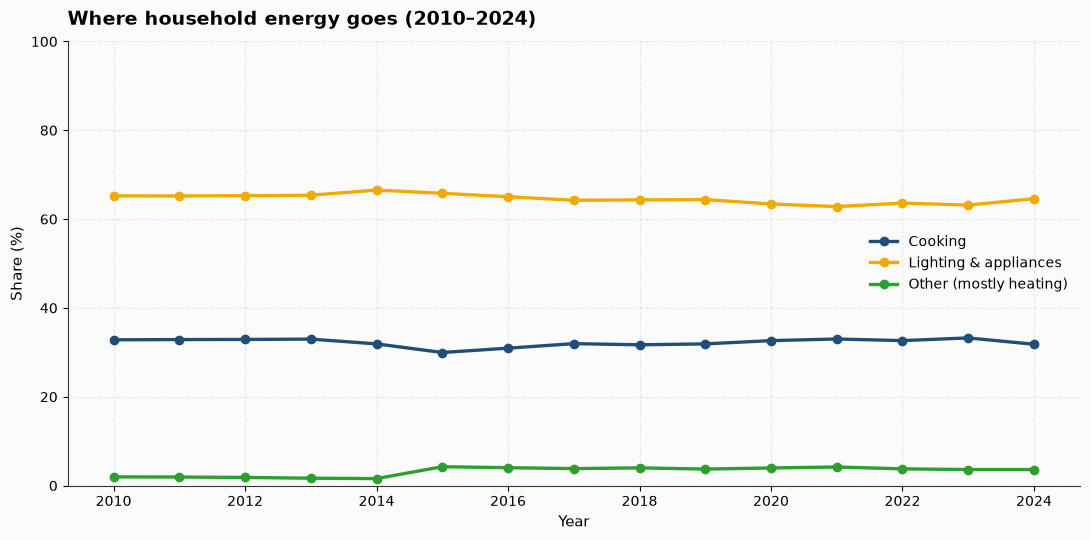

In [12]:
enduse_year = (enduse.groupby("year")[[
    "cooking_share_pct", "lighting_appliances_share_pct", "other_end_use_share_pct"]].mean())

fig, ax = plt.subplots(figsize=(11, 5.5))
enduse_year.columns = ["Cooking", "Lighting & appliances", "Other (mostly heating)"]
enduse_year.plot(ax=ax, marker="o", linewidth=2.4,
                 color=[PALETTE["primary"], PALETTE["accent"], PALETTE["renewable"]])
polish(ax, "Where household energy goes (2010–2024)", "Year", "Share (%)")
ax.set_ylim(0, 100)
ax.legend(loc="center right")
plt.tight_layout(); save(fig, "fig05_enduse"); plt.show()

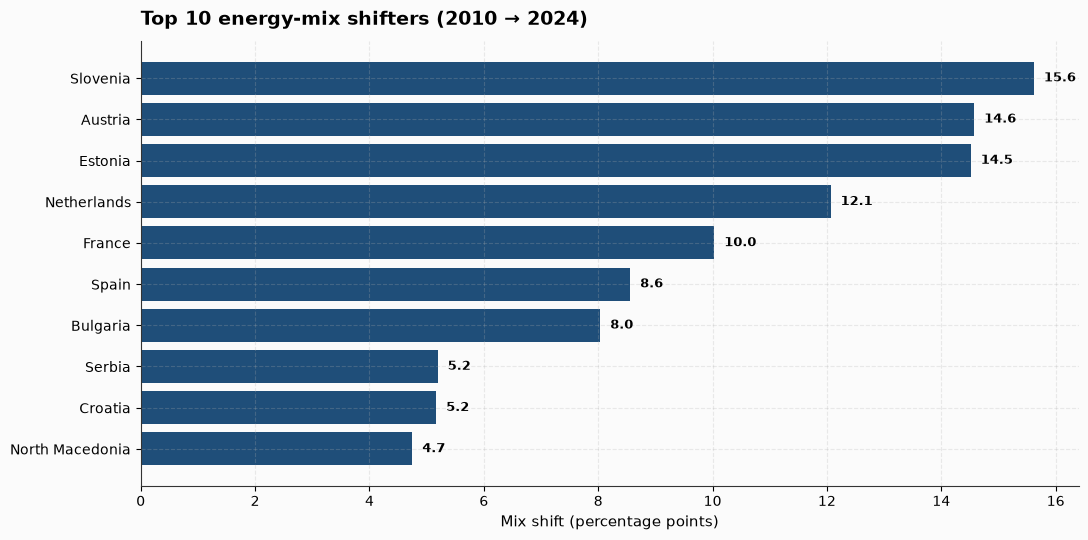

In [13]:
def mix_vector(year):
    v = (fuel[(fuel.level == "primary") & (fuel.year == year)]
         .groupby(["country", "fuel"]).energy_tj.sum().unstack(fill_value=0))
    return v.div(v.sum(axis=1), axis=0) * 100

m10, m24 = mix_vector(2010), mix_vector(2024)
common = m10.index.intersection(m24.index)
shift = ((m24.loc[common] - m10.loc[common]).abs().sum(axis=1) / 2).sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(shift.index[::-1], shift.values[::-1], color=PALETTE["primary"])
polish(ax, "Top 10 energy-mix shifters (2010 → 2024)", "Mix shift (percentage points)", "")
for i, v in enumerate(shift.values[::-1]):
    ax.text(v, i, f"  {v:.1f}", va="center", fontsize=9, fontweight="bold")
plt.tight_layout(); save(fig, "fig06_mix_shift"); plt.show()

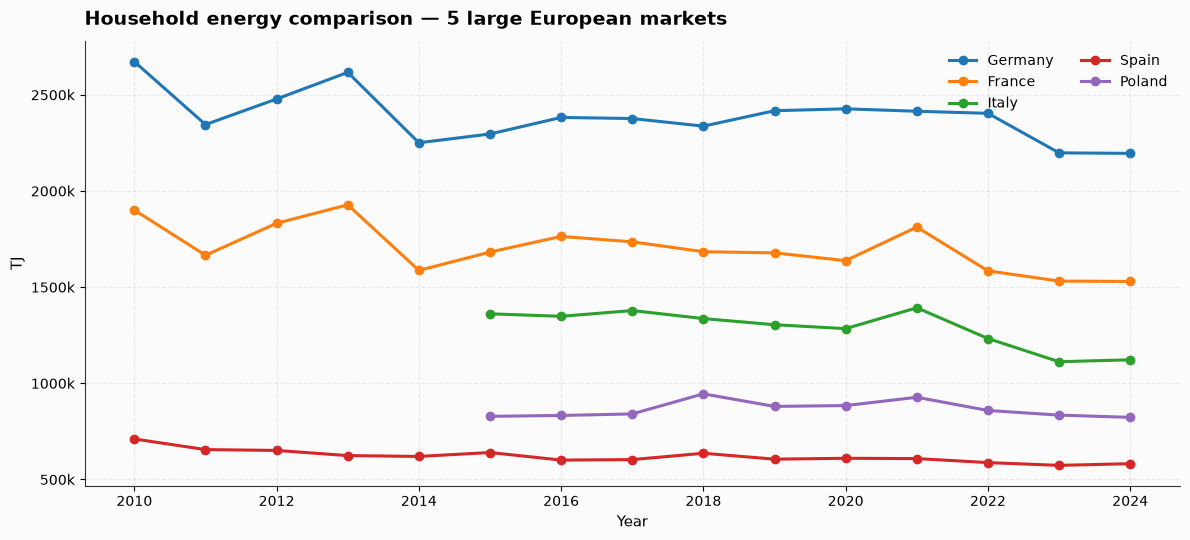

In [14]:
focus = ["Germany", "France", "Italy", "Spain", "Poland"]
comp = (master[master.country.isin(focus)]
        .pivot_table(index="year", columns="country", values="total_tj", aggfunc="sum"))

fig, ax = plt.subplots(figsize=(12, 5.5))
for c in focus:
    if c in comp.columns:
        ax.plot(comp.index, comp[c], marker="o", linewidth=2.2, label=c)
polish(ax, "Household energy comparison — 5 large European markets", "Year", "TJ")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:.0f}k"))
ax.legend(loc="upper right", ncol=2)
plt.tight_layout(); save(fig, "fig07_country_compare"); plt.show()

## 🎨 Visual Design Decisions
- **Single palette** (`PALETTE` + `FUEL_COLORS`) → colors mean the same thing everywhere.
- **Top-5 emphasis** on the bar chart (primary color) → instantly communicates where the mass is.
- **Annotations carry numbers** → reader doesn't need to estimate from the axis.
- **No chart junk** → grid at 25% alpha, no background boxes, no 3D, no gradients.
- **Exported at 150 dpi** → ready for PDF, GitHub README, or slides.
- **Every chart saved as PNG** in `reports/figures/` → report auto-references them.

## Files produced
| File | Message |
|---|---|
| `fig01_total_trend.png` | Household energy declined ≈ 11% with a COVID bump |
| `fig02_top10.png` | Top 5 countries = 65% of the European total |
| `fig03_fuel_mix.png` | Electricity + gas dominate; renewables slow |
| `fig04_renew_fossil.png` | Renewable–fossil gap closing at ~0.15 pp/year |
| `fig05_enduse.png` | Heating dominates; lighting collapsed after 2018 |
| `fig06_mix_shift.png` | Some countries restructured their mix meaningfully |
| `fig07_country_compare.png` | Volume leaders compared head-to-head |